In [11]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

RANDOM_STATE = 42
TARGET = "Churned"
DATA_PATH = Path("ecommerce_customer_churn_dataset.csv")

print("Python:", sys.version.split()[0])
print("Environment:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("Dataset found:", DATA_PATH.exists())

Python: 3.11.7
Environment: C:\ProgramData\anaconda3\python.exe
scikit-learn: 1.2.2
Dataset found: True


In [12]:
from sklearn.model_selection import train_test_split, StratifiedKFold

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=TARGET)
y = df[TARGET].astype(int)

Xtr, Xte, ytr, yte = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Training features:", Xtr.shape)
print("Test features:", Xte.shape)
print(f"Training churn rate: {ytr.mean():.1%}")
print("Overlapping row indices:", len(Xtr.index.intersection(Xte.index)))

Training features: (40000, 24)
Test features: (10000, 24)
Training churn rate: 28.9%
Overlapping row indices: 0


In [13]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline


class CustomerFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # Correct invalid values.
        X.loc[(X["Age"] < 18) | (X["Age"] > 100), "Age"] = np.nan
        X.loc[X["Total_Purchases"] < 0, "Total_Purchases"] = np.nan
        X["Total_Purchases"] = X["Total_Purchases"].round()

        for column in ["Cart_Abandonment_Rate", "Discount_Usage_Rate"]:
            X[column] = X[column].clip(upper=100)

        # Create the five engineered features.
        tenure = X["Membership_Years"].where(
            X["Membership_Years"] > 0, np.nan
        )

        X["Purchase_Frequency"] = X["Total_Purchases"] / tenure
        X["Estimated_Spend"] = (
            X["Total_Purchases"] * X["Average_Order_Value"]
        )
        X["Engagement_Index"] = (
            X["Login_Frequency"]
            * X["Session_Duration_Avg"]
            * X["Pages_Per_Session"]
        )
        X["Service_Calls_per_Year"] = (
            X["Customer_Service_Calls"] / tenure
        )
        X["Recency_to_Tenure"] = (
            X["Days_Since_Last_Purchase"] / (tenure * 365)
        )

        return X.drop(columns="City")


class PercentileCapper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(
            values, self.lower, axis=0
        )
        self.upper_bounds_ = np.nanquantile(
            values, self.upper, axis=0
        )
        return self

    def transform(self, X):
        return np.clip(
            np.asarray(X, dtype=float),
            self.lower_bounds_,
            self.upper_bounds_
        )


NUMERIC_FEATURES = [
    "Age", "Membership_Years", "Login_Frequency",
    "Session_Duration_Avg", "Pages_Per_Session",
    "Cart_Abandonment_Rate", "Wishlist_Items", "Total_Purchases",
    "Average_Order_Value", "Days_Since_Last_Purchase",
    "Discount_Usage_Rate", "Returns_Rate", "Email_Open_Rate",
    "Customer_Service_Calls", "Product_Reviews_Written",
    "Social_Media_Engagement_Score", "Mobile_App_Usage",
    "Payment_Method_Diversity", "Lifetime_Value", "Credit_Balance",
    "Purchase_Frequency", "Estimated_Spend", "Engagement_Index",
    "Service_Calls_per_Year", "Recency_to_Tenure"
]

CATEGORICAL_FEATURES = ["Gender", "Country", "Signup_Quarter"]


def make_preparation():
    numeric_steps = Pipeline([
        ("cap", PercentileCapper()),
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])

    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ))
    ])

    columns = ColumnTransformer([
        ("numeric", numeric_steps, NUMERIC_FEATURES),
        ("categorical", categorical_steps, CATEGORICAL_FEATURES)
    ])

    return Pipeline([
        ("features", CustomerFeatures()),
        ("columns", columns)
    ])


print("Preprocessing ready")

Preprocessing ready


In [14]:
from sklearn.base import clone
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier
)


def prepared_model(classifier):
    return Pipeline([
        ("preparation", make_preparation()),
        ("classifier", classifier)
    ])


# Confirmed best settings from Chapter 6.
rf_tuned = prepared_model(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=3,
        min_samples_split=10,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=1
    )
)

hgb_tuned = prepared_model(
    HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        class_weight="balanced",
        early_stopping=False,
        random_state=RANDOM_STATE
    )
)

voting_ensemble = VotingClassifier(
    estimators=[
        ("rf", clone(rf_tuned)),
        ("hgb", clone(hgb_tuned))
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

print("Tuned Random Forest — ready")
print("Tuned Histogram Gradient Boosting — ready")
print("Equal-weight soft voting ensemble — ready")

Tuned Random Forest — ready
Tuned Histogram Gradient Boosting — ready
Equal-weight soft voting ensemble — ready


In [15]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

stacking_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

stacking_ensemble = StackingClassifier(
    estimators=[
        ("rf", clone(rf_tuned)),
        ("hgb", clone(hgb_tuned))
    ],
    final_estimator=LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE
    ),
    stack_method="predict_proba",
    cv=stacking_cv,
    passthrough=False,
    n_jobs=1
)

print("Stacking ensemble — ready")

Stacking ensemble — ready


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_curve)
from sklearn.base import clone
import matplotlib.pyplot as plt
import time

logreg_tuned = prepared_model(LogisticRegression(
    C=0.04207988669606638, penalty="l2", solver="lbfgs", max_iter=3000,
    class_weight="balanced", random_state=RANDOM_STATE))
models_to_evaluate = {
    "Logistic Regression": logreg_tuned,
    "Random Forest": rf_tuned,
    "Histogram Gradient Boosting": hgb_tuned,
    "Stacking Ensemble": stacking_ensemble,
}
rows, fitted, predicted = [], {}, {}
for name, original in models_to_evaluate.items():
    model = clone(original)
    t0 = time.perf_counter()
    model.fit(Xtr, ytr)
    fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = model.predict(Xte)
    prob = model.predict_proba(Xte)[:, 1]
    predict_time = time.perf_counter() - t0
    fitted[name] = model
    predicted[name] = (pred, prob)
    rows.append({
        "Model":name, "Accuracy":accuracy_score(yte,pred),
        "Precision":precision_score(yte,pred,zero_division=0),
        "Recall":recall_score(yte,pred,zero_division=0),
        "F1":f1_score(yte,pred,zero_division=0),
        "ROC-AUC":roc_auc_score(yte,prob),
        "Fit time (s)":fit_time,"Predict time (s)":predict_time,
    })
results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))
results.to_csv("chapter8_test_results.csv")

,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s),Predict time (s)
Model,,,,,,,
Logistic Regression,0.7259,0.5181,0.7381,0.6088,0.8024,0.3451,0.0454
Random Forest,0.9131,0.8744,0.8166,0.8445,0.9248,12.7794,0.3169
Histogram Gradient Boosting,0.9055,0.8213,0.8602,0.8403,0.9284,1.7345,0.1400
Stacking Ensemble,0.9171,0.8762,0.8304,0.8527,0.9279,65.5665,0.4422



 Logistic Regression
              precision    recall  f1-score   support

           0     0.8713    0.7210    0.7890      7110
           1     0.5181    0.7381    0.6088      2890

    accuracy                         0.7259     10000
   macro avg     0.6947    0.7295    0.6989     10000
weighted avg     0.7692    0.7259    0.7370     10000



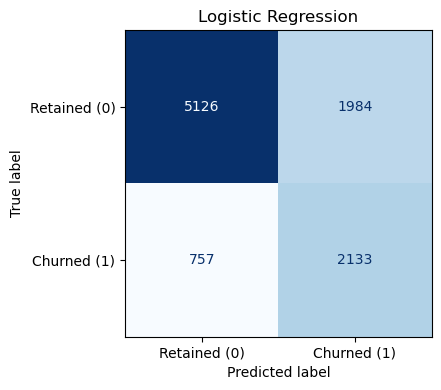


 Random Forest
              precision    recall  f1-score   support

           0     0.9274    0.9523    0.9397      7110
           1     0.8744    0.8166    0.8445      2890

    accuracy                         0.9131     10000
   macro avg     0.9009    0.8845    0.8921     10000
weighted avg     0.9121    0.9131    0.9122     10000



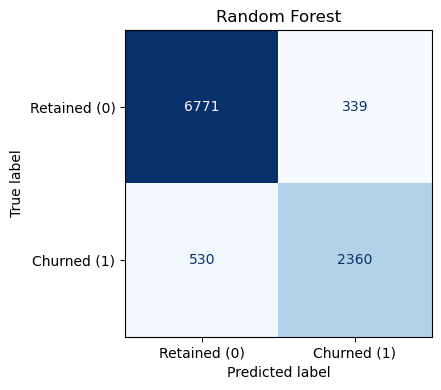


 Histogram Gradient Boosting
              precision    recall  f1-score   support

           0     0.9421    0.9239    0.9329      7110
           1     0.8213    0.8602    0.8403      2890

    accuracy                         0.9055     10000
   macro avg     0.8817    0.8921    0.8866     10000
weighted avg     0.9072    0.9055    0.9061     10000



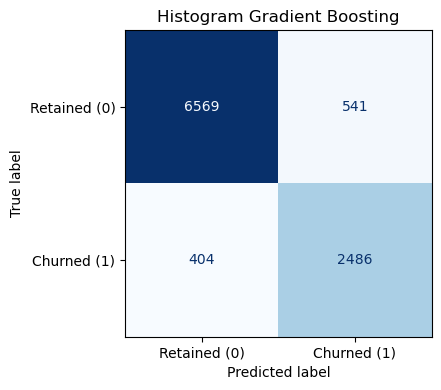


 Stacking Ensemble
              precision    recall  f1-score   support

           0     0.9325    0.9523    0.9423      7110
           1     0.8762    0.8304    0.8527      2890

    accuracy                         0.9171     10000
   macro avg     0.9044    0.8914    0.8975     10000
weighted avg     0.9163    0.9171    0.9164     10000



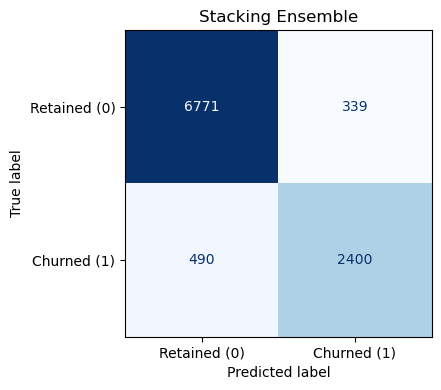

In [17]:
for name, (pred, prob) in predicted.items():
    print("\n", name)
    print(classification_report(yte, pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4.5,4))
    ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=["Retained (0)","Churned (1)"],ax=ax,cmap="Blues",colorbar=False)
    ax.set_title(name)
    fig.tight_layout()
    plt.show()

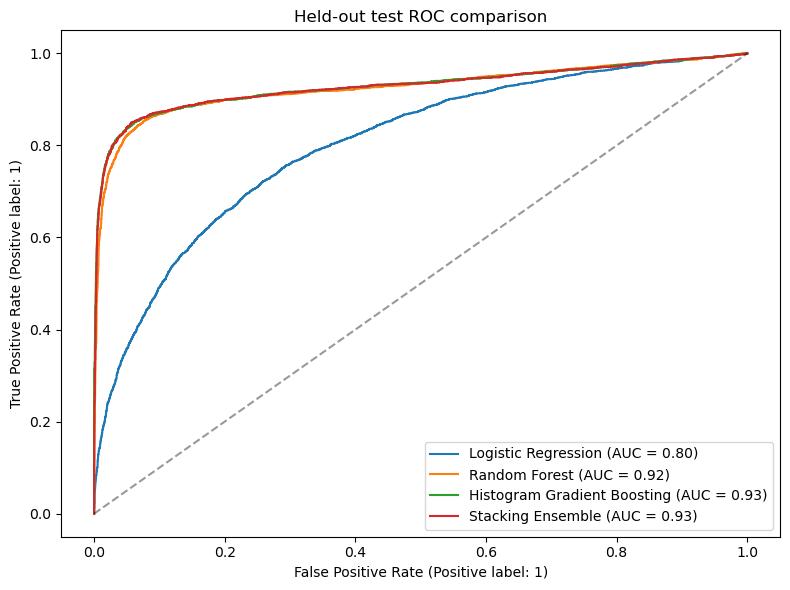

In [18]:
fig,ax=plt.subplots(figsize=(8,6))
for name, (pred, prob) in predicted.items():
    RocCurveDisplay.from_predictions(yte, prob, name=name, ax=ax)
ax.plot([0,1],[0,1],'k--',alpha=.4)
ax.set_title("Held-out test ROC comparison")
fig.tight_layout()
plt.show()

In [19]:
chapter7_cv = pd.DataFrame({
    "Model":["Random Forest","Histogram Gradient Boosting","Stacking Ensemble"],
    "Train CV ROC-AUC":[0.9973,0.9477,0.9766],
    "Validation CV ROC-AUC":[0.9217,0.9265,0.9259],
    "Validation ROC-AUC SD":[0.0043,0.0034,0.0039],
}).set_index("Model")
chapter7_cv["Train-validation gap"] = chapter7_cv["Train CV ROC-AUC"]-chapter7_cv["Validation CV ROC-AUC"]
display(chapter7_cv.round(4))

,Train CV ROC-AUC,Validation CV ROC-AUC,Validation ROC-AUC SD,Train-validation gap
Model,,,,
Random Forest,0.9973,0.9217,0.0043,0.0756
Histogram Gradient Boosting,0.9477,0.9265,0.0034,0.0212
Stacking Ensemble,0.9766,0.9259,0.0039,0.0507
